# Employee Data Quality & Human Capital Analytics
## Exploratory Data Analysis (EDA)

**Dataset:** Human Resources Data Set (HRDataset_v14)  
**Sumber:** [Kaggle — Human Resources Data Set](https://www.kaggle.com/datasets/rhuebner/human-resources-data-set)  
**Tools:** Google Colab, Python, Pandas, Matplotlib  
**Tahap sebelumnya:** Data Cleaning & Validation

Notebook ini mengeksplorasi struktur tenaga kerja, status kepegawaian, tren perekrutan, kinerja, kepuasan, keterlibatan pegawai, dan absensi. Hasil EDA akan digunakan untuk menentukan indikator pada dashboard Power BI.

Dataset merupakan **data sintetis dari perusahaan fiktif**, bukan data pegawai BPK Kupang atau Pegadaian. Seluruh analisis menggunakan kolom asli dataset; tidak ada atribut baru yang ditambahkan ke tabel utama.

## 1. Research Questions

Analisis berfokus pada pertanyaan berikut:

1. Bagaimana komposisi pegawai berdasarkan departemen dan status kerja?
2. Bagaimana distribusi kategori penilaian kinerja pada setiap departemen?
3. Apakah terdapat pola antara kepuasan, keterlibatan pegawai, dan kinerja?
4. Bagaimana perbedaan absensi dan keterlambatan antar kelompok pegawai?
5. Bagaimana tren perekrutan dan alasan terminasi pada data historis?

**Batasan:** Dataset memuat pegawai aktif dan yang sudah terminasi. Jumlah seluruh record adalah *historical roster*, bukan jumlah pegawai aktif pada satu tanggal tertentu. Jumlah terminasi dibagi total record juga **bukan** tingkat turnover tahunan.

## 2. Load the Cleaned Dataset

Notebook ini berdiri sendiri, sehingga tidak memerlukan variabel dari notebook data cleaning. Upload file `HRDataset_v14_clean.csv` atau ZIP hasil cleaning (`HR_Analytics_Cleaned_Output.zip`).

File CSV asli dari Kaggle tidak digunakan pada tahap ini, karena analisis dilakukan pada data yang telah distandardisasi dan divalidasi.

In [ ]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Upload satu file CSV cleaned atau ZIP hasil cleaning.")

filename, file_bytes = next(iter(uploaded.items()))
quality_report = None
review_records = None

if filename.lower().endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(file_bytes)) as archive:
        target = [name for name in archive.namelist()
                  if Path(name).name.lower() == "hrdataset_v14_clean.csv"]
        if not target:
            raise FileNotFoundError("HRDataset_v14_clean.csv tidak ditemukan di dalam ZIP.")
        df = pd.read_csv(io.BytesIO(archive.read(target[0])))

        quality_file = [name for name in archive.namelist()
                        if Path(name).name.lower() == "data_quality_report.csv"]
        if quality_file:
            quality_report = pd.read_csv(io.BytesIO(archive.read(quality_file[0])))

        review_file = [name for name in archive.namelist()
                       if Path(name).name.lower() == "records_for_review.csv"]
        if review_file:
            review_records = pd.read_csv(io.BytesIO(archive.read(review_file[0])))

elif filename.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(file_bytes))
else:
    raise ValueError("Gunakan file CSV atau ZIP.")

print(f"File dimuat: {filename}")
print(f"Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
display(df.head(3))

Saving HRDataset_v14_clean.csv to HRDataset_v14_clean (1).csv
File dimuat: HRDataset_v14_clean (1).csv
Dataset: 311 baris, 36 kolom


,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,...,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,2019-01-17,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,...,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2016-02-24,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,...,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,2012-05-15,0,3


### 2.1 Dataset Integrity Check

Kita memastikan identitas pegawai tetap unik dan seluruh kolom yang dibutuhkan tersedia. Tanggal dibaca ulang sebagai `datetime` agar bisa digunakan untuk analisis waktu; perubahan ini tidak menambah kolom.

In [ ]:
required_columns = [
    "EmpID", "Department", "EmploymentStatus", "Termd",
    "PerformanceScore", "EngagementSurvey", "EmpSatisfaction",
    "Absences", "DaysLateLast30", "Salary", "DateofHire",
    "DateofTermination", "TermReason", "RecruitmentSource"
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Kolom belum tersedia: {missing_columns}")

for col in ["DOB", "DateofHire", "DateofTermination", "LastPerformanceReview_Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed", dayfirst=False)

assert df["EmpID"].is_unique, "EmpID belum unik. Periksa hasil cleaning."

print("Total pegawai unik:", df["EmpID"].nunique())
print("Jumlah kolom:", df.shape[1])
print("Rentang tanggal perekrutan:", df["DateofHire"].min().date(), "s.d.", df["DateofHire"].max().date())
display(df.dtypes.value_counts().rename("Jumlah Kolom"))

Total pegawai unik: 311
Jumlah kolom: 36
Rentang tanggal perekrutan: 2006-01-09 s.d. 2018-07-09


,Jumlah Kolom
int64,16
object,14
datetime64[ns],4
float64,2


## 3. Data Quality Recap

Ringkasan kualitas data dari notebook sebelumnya digunakan sebagai konteks. Jika ZIP memuat `data_quality_report.csv`, hasilnya dapat ditampilkan di sini. Temuan kategori *Review* tidak otomatis berarti record salah dan tidak dihapus dari analisis.

In [ ]:
if quality_report is not None:
    display(quality_report)
else:
    print("Laporan validasi tidak ada pada file yang diunggah. Gunakan laporan dari notebook cleaning.")

if review_records is not None:
    print("Temuan yang tercatat:", len(review_records))
    print("Pegawai unik perlu review:", review_records["EmpID"].nunique())

print("Missing values pada dataset EDA:")
display(df.isna().sum().loc[lambda s: s.gt(0)].sort_values(ascending=False).to_frame("Missing Values"))

Laporan validasi tidak ada pada file yang diunggah. Gunakan laporan dari notebook cleaning.
Missing values pada dataset EDA:


,Missing Values
DateofTermination,207
ManagerID,8


## 4. Workforce Overview

Pertama, kita menghitung jumlah pegawai unik, status aktif berdasarkan `Termd`, dan jumlah departemen. Semua angka bersumber dari dataset, bukan asumsi.

**Definisi:** `Termd = 0` berarti belum terminasi, sedangkan `Termd = 1` berarti telah terminasi. Nilai tersebut merepresentasikan status pada cakupan dataset, bukan status tenaga kerja saat ini di dunia nyata.

In [ ]:
overview = pd.DataFrame({
    "Metric": ["Unique employee records", "Not terminated (Termd = 0)",
               "Terminated (Termd = 1)", "Departments"],
    "Value": [
        df["EmpID"].nunique(),
        int(df["Termd"].eq(0).sum()),
        int(df["Termd"].eq(1).sum()),
        df["Department"].nunique()
    ]
})
display(overview)

employment_summary = (
    df.groupby("EmploymentStatus", dropna=False)["EmpID"]
    .nunique().sort_values(ascending=False)
)
display(employment_summary.to_frame("Employees"))

,Metric,Value
0,Unique employee records,311
1,Not terminated (Termd = 0),207
2,Terminated (Termd = 1),104
3,Departments,6


,Employees
EmploymentStatus,
Active,207
Voluntarily Terminated,88
Terminated for Cause,16


### 4.1 Employee Distribution by Department

Grafik menunjukkan jumlah record pegawai pada setiap departemen, termasuk pegawai yang sudah berhenti. Komposisi ini tidak sama dengan jumlah pegawai aktif per departemen.

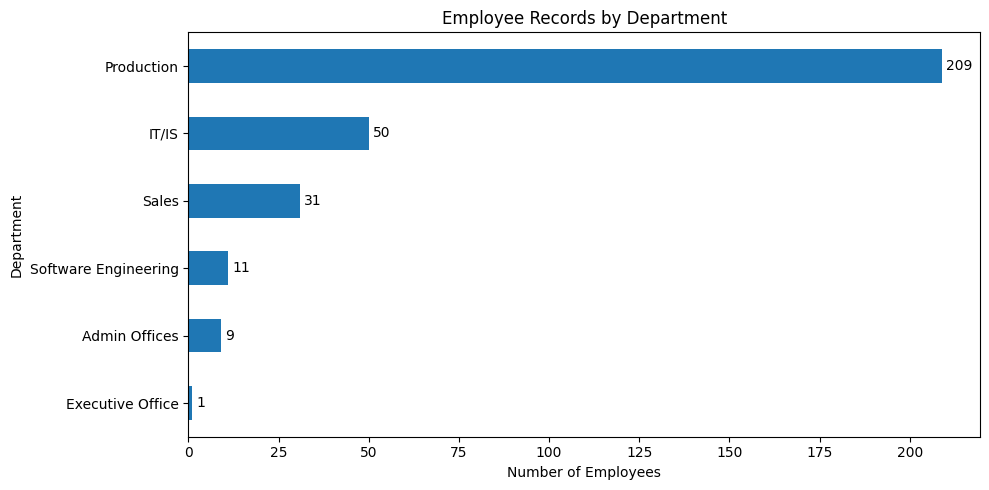

,Employees
Department,
Production,209
IT/IS,50
Sales,31
Software Engineering,11
Admin Offices,9
Executive Office,1


In [ ]:
department_counts = (
    df.groupby("Department")["EmpID"]
    .nunique().sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))
department_counts.plot(kind="barh", ax=ax)
ax.set(title="Employee Records by Department", xlabel="Number of Employees", ylabel="Department")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

display(department_counts.sort_values(ascending=False).to_frame("Employees"))

### 4.2 Employment Status by Department

Perbandingan status kerja membantu memahami apakah komposisi pegawai aktif dan terminasi berbeda antar-departemen. Grafik menggunakan jumlah record, sehingga tidak dapat langsung ditafsirkan sebagai tingkat turnover.

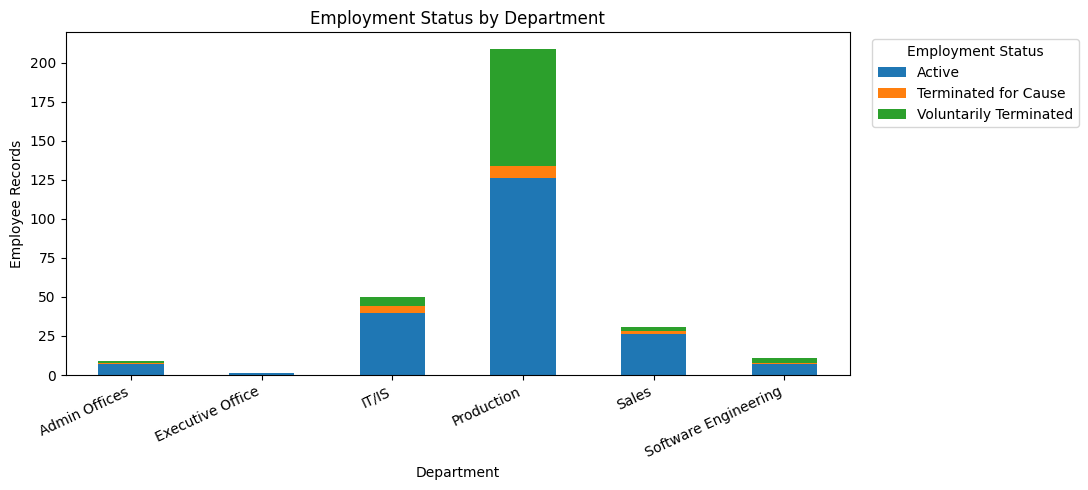

EmploymentStatus,Active,Terminated for Cause,Voluntarily Terminated
Department,,,
Admin Offices,7,1,1
Executive Office,1,0,0
IT/IS,40,4,6
Production,126,8,75
Sales,26,2,3
Software Engineering,7,1,3


In [ ]:
department_status = pd.crosstab(df["Department"], df["EmploymentStatus"])
ax = department_status.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set(title="Employment Status by Department", xlabel="Department", ylabel="Employee Records")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Employment Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(department_status)

## 5. Hiring and Termination Patterns

Kita menganalisis jumlah perekrutan berdasarkan tahun dan alasan terminasi yang tercatat.

**Perhatian:** Grafik perekrutan menunjukkan berapa orang dalam dataset yang memiliki `DateofHire` pada tahun tersebut. Ini bukan perubahan *headcount* atau jumlah lowongan. Dataset juga tidak dapat digunakan untuk menggambarkan kondisi terbaru perusahaan di luar periode pencatatannya.

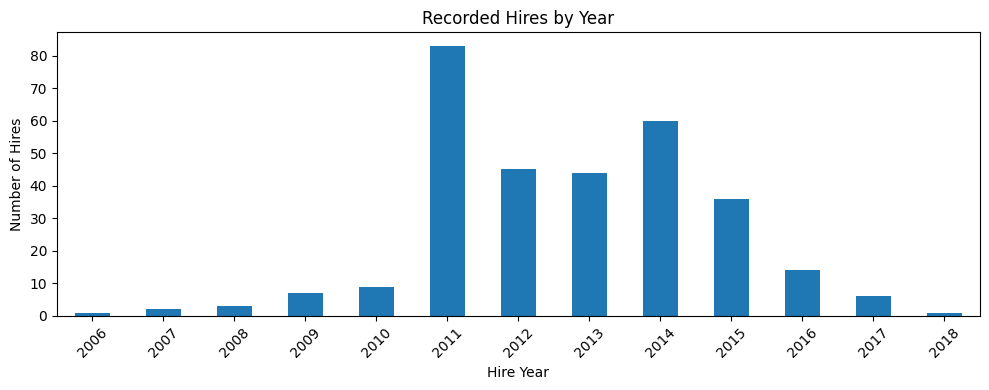

,Hires
Hire Year,
2006,1
2007,2
2008,3
2009,7
2010,9
2011,83
2012,45
2013,44
2014,60


In [ ]:
hires_by_year = (
    df["DateofHire"].dropna().dt.year
    .value_counts().sort_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
hires_by_year.plot(kind="bar", ax=ax)
ax.set(title="Recorded Hires by Year", xlabel="Hire Year", ylabel="Number of Hires")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(hires_by_year.rename_axis("Hire Year").to_frame("Hires"))

### 5.1 Termination Reasons

Alasan terminasi dihitung hanya untuk record dengan `Termd = 1`. Tujuannya mengidentifikasi alasan yang paling sering tercatat, bukan menjelaskan penyebab mendasar keputusan pegawai.

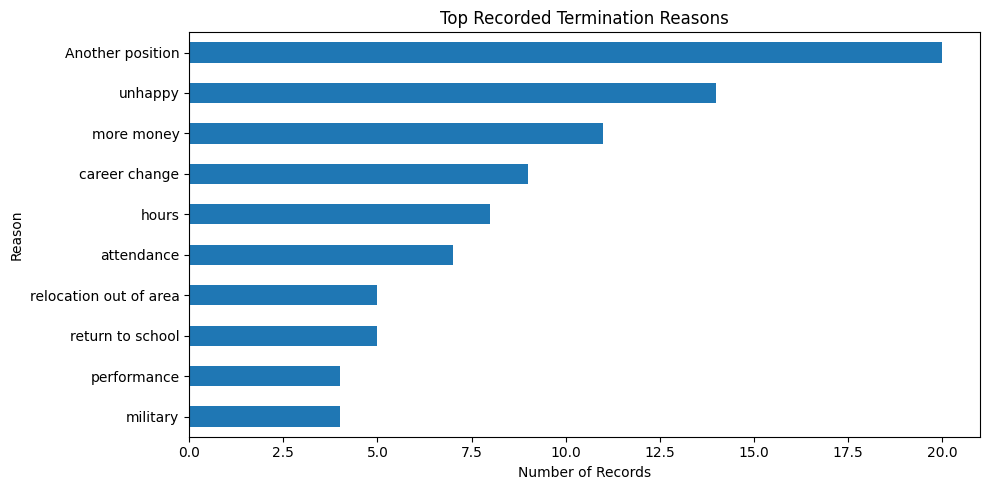

,Records
TermReason,
Another position,20
unhappy,14
more money,11
career change,9
hours,8
attendance,7
return to school,5
relocation out of area,5
performance,4


In [ ]:
terminated = df.loc[df["Termd"].eq(1)]
reason_counts = (
    terminated["TermReason"]
    .fillna("Not recorded")
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))
reason_counts.plot(kind="barh", ax=ax)
ax.set(title="Top Recorded Termination Reasons", xlabel="Number of Records", ylabel="Reason")
plt.tight_layout()
plt.show()

display(reason_counts.sort_values(ascending=False).to_frame("Records"))

## 6. Employee Performance

`PerformanceScore` merupakan kategori penilaian kinerja, sehingga kita tidak mengasumsikan jarak antar-kategori bersifat numerik. Kita mulai dengan frekuensi kategori, kemudian membandingkan komposisinya berdasarkan departemen.

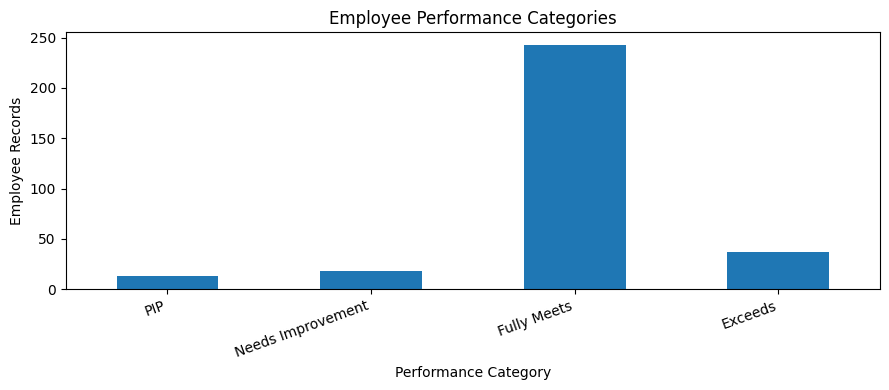

,Employees
PerformanceScore,
PIP,13
Needs Improvement,18
Fully Meets,243
Exceeds,37


In [ ]:
performance_order = ["PIP", "Needs Improvement", "Partially Meets", "Fully Meets", "Exceeds"]
observed = df["PerformanceScore"].dropna().unique().tolist()
ordered_labels = [label for label in performance_order if label in observed]
ordered_labels += sorted(set(observed) - set(ordered_labels))
performance_counts = df["PerformanceScore"].value_counts().reindex(ordered_labels, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4))
performance_counts.plot(kind="bar", ax=ax)
ax.set(title="Employee Performance Categories", xlabel="Performance Category", ylabel="Employee Records")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

display(performance_counts.to_frame("Employees"))

### 6.1 Performance Mix by Department

Karena ukuran departemen berbeda, persentase per departemen lebih mudah dibandingkan daripada jumlah absolut. Nilai 100% pada satu baris menunjukkan distribusi seluruh kategori penilaian pada departemen tersebut.

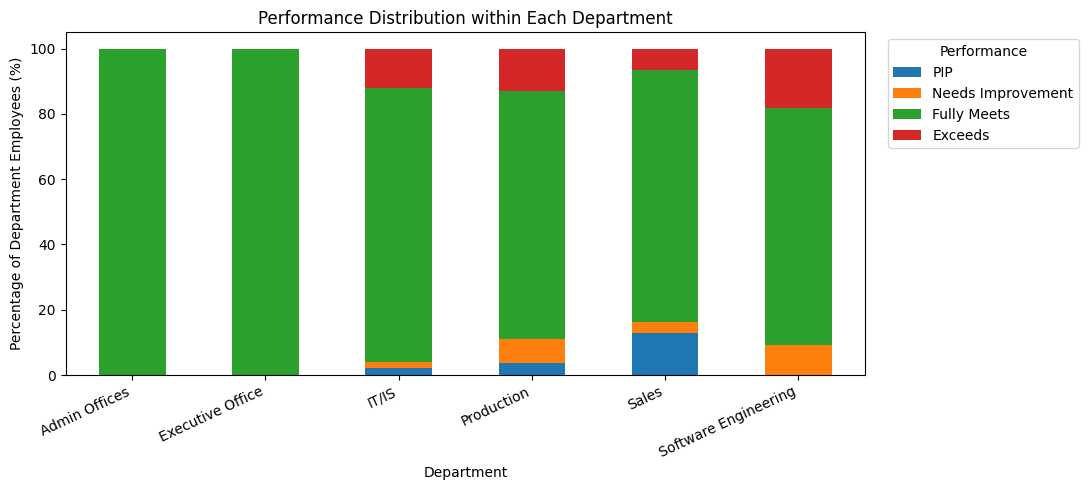

PerformanceScore,PIP,Needs Improvement,Fully Meets,Exceeds
Department,,,,
Admin Offices,0.0,0.0,100.0,0.0
Executive Office,0.0,0.0,100.0,0.0
IT/IS,2.0,2.0,84.0,12.0
Production,3.8,7.2,76.1,12.9
Sales,12.9,3.2,77.4,6.5
Software Engineering,0.0,9.1,72.7,18.2


In [ ]:
performance_pct = pd.crosstab(
    df["Department"], df["PerformanceScore"], normalize="index"
).mul(100)
performance_pct = performance_pct.reindex(columns=ordered_labels, fill_value=0)

ax = performance_pct.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set(title="Performance Distribution within Each Department", xlabel="Department",
       ylabel="Percentage of Department Employees (%)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Performance", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(performance_pct.round(1))

## 7. Employee Engagement & Satisfaction

`EngagementSurvey` dan `EmpSatisfaction` memberikan dua ukuran berbeda tentang pengalaman pegawai. Kita memeriksa hubungan keduanya secara deskriptif; hubungan statistik tidak membuktikan hubungan sebab-akibat.

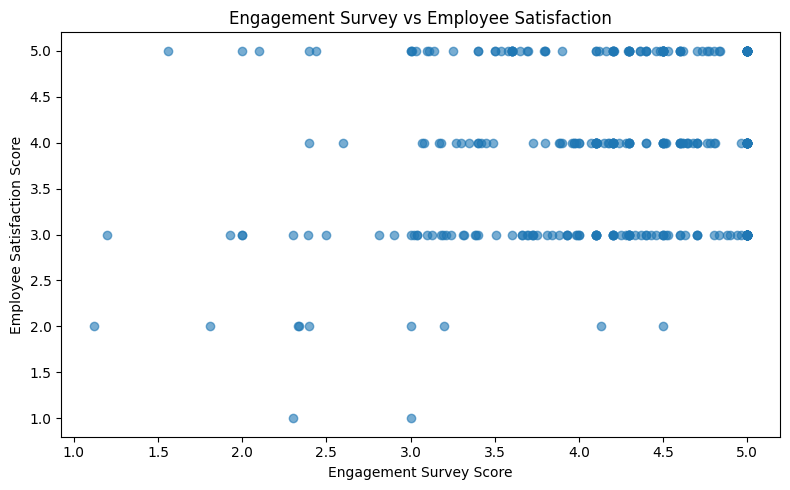

Pearson correlation: 0.187


,EngagementSurvey,EmpSatisfaction
Department,,
Admin Offices,4.39,3.56
Executive Office,4.83,3.00
IT/IS,4.15,3.96
Production,4.13,3.86
Sales,3.82,4.03
Software Engineering,4.06,4.09


In [ ]:
engagement = pd.to_numeric(df["EngagementSurvey"], errors="coerce")
satisfaction = pd.to_numeric(df["EmpSatisfaction"], errors="coerce")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(engagement, satisfaction, alpha=0.6)
ax.set(title="Engagement Survey vs Employee Satisfaction",
       xlabel="Engagement Survey Score", ylabel="Employee Satisfaction Score")
plt.tight_layout()
plt.show()

print("Pearson correlation:", round(engagement.corr(satisfaction), 3))

engagement_by_dept = (
    df.groupby("Department")[["EngagementSurvey", "EmpSatisfaction"]]
    .mean().round(2)
)
display(engagement_by_dept)

## 8. Attendance Patterns

Analisis absensi dilakukan dengan membandingkan jumlah absensi pada kelompok kinerja. Kita juga melihat rata-rata keterlambatan 30 hari terakhir per departemen.

Periode pengukuran `Absences` tidak dinyatakan setara dengan `DaysLateLast30` dalam dataset. Karena itu, kedua metrik tidak digabung menjadi satu rasio dan tidak ditafsirkan sebagai penyebab kinerja.

,Employees,Median_Absences,Mean_Absences,Mean_Late_Last30
PerformanceScore,,,,
Exceeds,37,12.0,10.49,0.00
Fully Meets,243,10.0,10.22,0.02
Needs Improvement,18,14.0,11.33,3.78
PIP,13,6.0,8.31,4.31


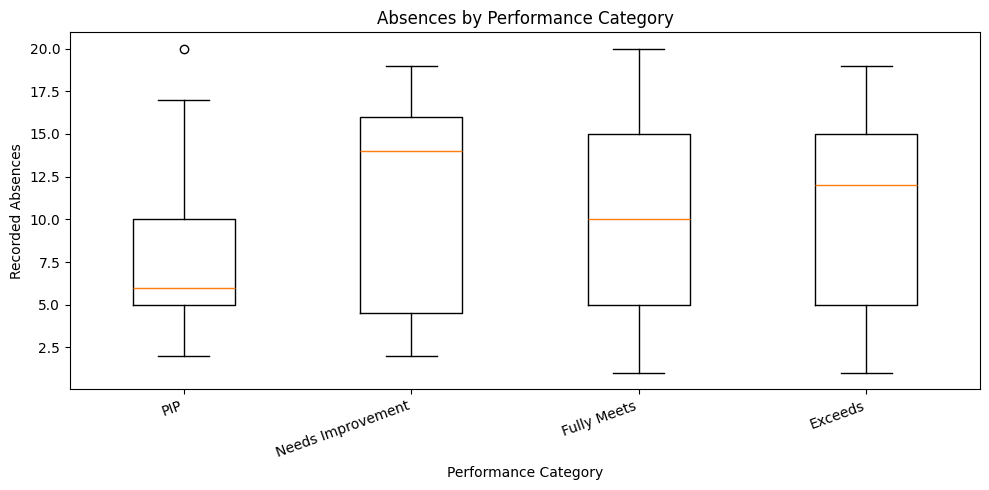

In [ ]:
absence_summary = (
    df.groupby("PerformanceScore", dropna=False)
    .agg(
        Employees=("EmpID", "nunique"),
        Median_Absences=("Absences", "median"),
        Mean_Absences=("Absences", "mean"),
        Mean_Late_Last30=("DaysLateLast30", "mean")
    )
    .round(2)
)
display(absence_summary)

plot_data = [
    df.loc[df["PerformanceScore"].eq(label), "Absences"].dropna().values
    for label in ordered_labels
]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(plot_data, tick_labels=ordered_labels)
ax.set(title="Absences by Performance Category", xlabel="Performance Category", ylabel="Recorded Absences")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 8.1 Lateness by Department

Rata-rata keterlambatan dihitung berdasarkan `DaysLateLast30`. Hasilnya merupakan gambaran deskriptif dan perlu dibaca bersama jumlah pegawai pada setiap departemen.

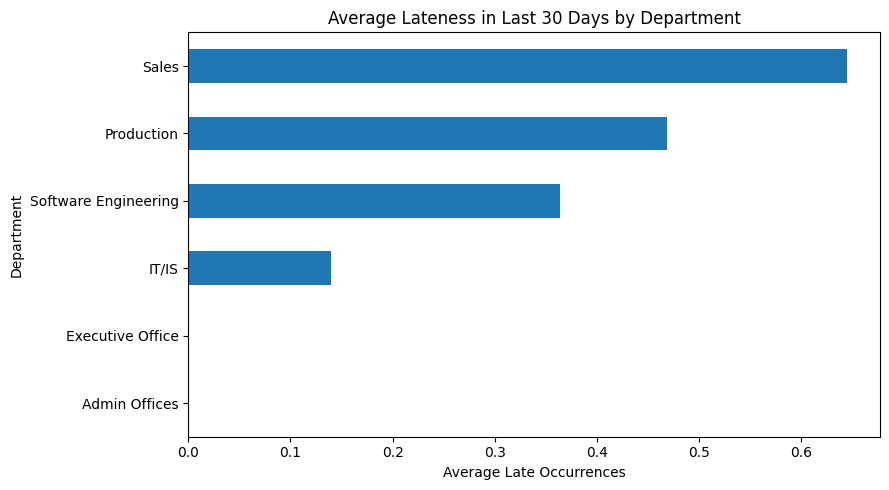

,Employees,Avg_Late_Last30
Department,,
Admin Offices,9,0.00
Executive Office,1,0.00
IT/IS,50,0.14
Software Engineering,11,0.36
Production,209,0.47
Sales,31,0.65


In [ ]:
lateness_by_dept = (
    df.groupby("Department")
    .agg(Employees=("EmpID", "nunique"),
         Avg_Late_Last30=("DaysLateLast30", "mean"))
    .sort_values("Avg_Late_Last30")
)

fig, ax = plt.subplots(figsize=(9, 5))
lateness_by_dept["Avg_Late_Last30"].plot(kind="barh", ax=ax)
ax.set(title="Average Lateness in Last 30 Days by Department", xlabel="Average Late Occurrences", ylabel="Department")
plt.tight_layout()
plt.show()

display(lateness_by_dept.round(2))

## 9. Recruitment Sources

Distribusi sumber rekrutmen dapat membantu memahami kanal yang paling banyak tercatat dalam riwayat perekrutan. Jumlah pegawai per kanal saja belum cukup untuk menilai biaya, efektivitas, ataupun kualitas hasil rekrutmen.

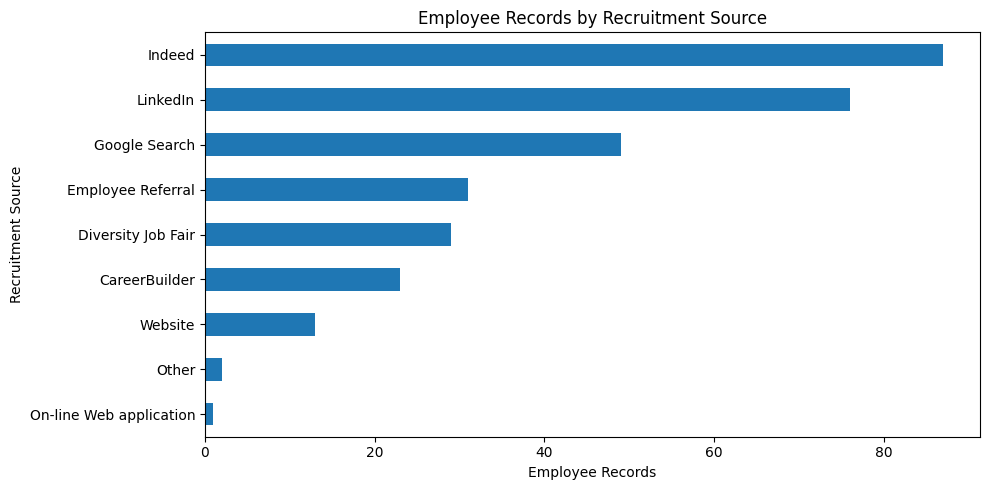

,Employee Records
RecruitmentSource,
Indeed,87
LinkedIn,76
Google Search,49
Employee Referral,31
Diversity Job Fair,29
CareerBuilder,23
Website,13
Other,2
On-line Web application,1


In [ ]:
recruitment_counts = (
    df["RecruitmentSource"]
    .fillna("Not recorded")
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))
recruitment_counts.plot(kind="barh", ax=ax)
ax.set(title="Employee Records by Recruitment Source", xlabel="Employee Records", ylabel="Recruitment Source")
plt.tight_layout()
plt.show()

display(recruitment_counts.sort_values(ascending=False).to_frame("Employee Records"))

## 10. Dashboard KPI Reference

Berikut ringkasan metrik yang dapat menjadi dasar halaman dashboard Power BI. Angka diperoleh langsung dari dataset yang dimuat. Tabel ringkasan yang diekspor adalah hasil agregasi untuk analisis, bukan penambahan kolom atau data simulasi ke dataset utama.

In [ ]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Employee records", "Not terminated", "Terminated", "Departments",
        "Average engagement score", "Average satisfaction score", "Average absences"
    ],
    "Value": [
        df["EmpID"].nunique(),
        df["Termd"].eq(0).sum(),
        df["Termd"].eq(1).sum(),
        df["Department"].nunique(),
        engagement.mean(), satisfaction.mean(),
        pd.to_numeric(df["Absences"], errors="coerce").mean()
    ]
})
display(kpi_summary.round(2))
print("Original dataset columns unchanged:", df.shape[1])

,Metric,Value
0,Employee records,311.00
1,Not terminated,207.00
2,Terminated,104.00
3,Departments,6.00
4,Average engagement score,4.11
5,Average satisfaction score,3.89
6,Average absences,10.24


Original dataset columns unchanged: 36



### Recorded Termination Share by Department

Analisis ini membandingkan jumlah pegawai yang tercatat telah mengalami terminasi terhadap total pegawai pada masing-masing departemen.

Perhitungan dilakukan untuk melihat perbedaan proporsi terminasi antar departemen, sehingga hasilnya tidak hanya dipengaruhi oleh besarnya jumlah pegawai.

Proporsi ini merupakan gambaran status pegawai dalam dataset dan bukan tingkat turnover tahunan.


In [ ]:

department_termination = (
    df.groupby("Department")
    .agg(
        Total_Employees=("EmpID", "nunique"),
        Terminated=("Termd", "sum")
    )
)

department_termination["Termination_Share (%)"] = (
    department_termination["Terminated"] /
    department_termination["Total_Employees"] * 100
).round(2)

department_termination = department_termination.sort_values(
    "Termination_Share (%)",
    ascending=False
)

display(department_termination)

,Total_Employees,Terminated,Termination_Share (%)
Department,,,
Production,209,83,39.71
Software Engineering,11,4,36.36
Admin Offices,9,2,22.22
IT/IS,50,10,20.00
Sales,31,5,16.13
Executive Office,1,0,0.00


## 11. Export Analysis Summaries (Optional)

Tabel ringkasan dapat dipakai sebagai referensi desain Power BI atau lampiran dokumentasi GitHub. Untuk dashboard Power BI utama, tetap gunakan `HRDataset_v14_clean.csv`, sehingga filter antarvisual bekerja berdasarkan record pegawai yang sama.

Jangan mengunggah ulang CSV asli atau turunannya secara publik tanpa mempertimbangkan ketentuan lisensi dataset. Notebook dan kode dapat dibagikan bersama tautan ke sumber Kaggle.

In [ ]:
from google.colab import files
import shutil

export_dir = Path("/content/hr_eda_outputs")
export_dir.mkdir(parents=True, exist_ok=True)

kpi_summary.to_csv(export_dir / "kpi_summary.csv", index=False)
department_status.to_csv(export_dir / "department_status_summary.csv")
performance_pct.to_csv(export_dir / "performance_by_department_pct.csv")
absence_summary.to_csv(export_dir / "attendance_by_performance.csv")
hires_by_year.to_csv(export_dir / "hires_by_year.csv", header=["Hires"])

archive = shutil.make_archive("/content/HR_EDA_Summaries", "zip", export_dir)
print("Summary tables saved:", [p.name for p in export_dir.iterdir()])
files.download(archive)

Summary tables saved: ['hires_by_year.csv', 'attendance_by_performance.csv', 'kpi_summary.csv', 'performance_by_department_pct.csv', 'department_status_summary.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## EDA Summary & Key Findings

Exploratory Data Analysis dilakukan terhadap 311 record pegawai dengan 36 atribut. Analisis mencakup distribusi tenaga kerja, status kepegawaian, perekrutan, kinerja, kepuasan kerja, keterlibatan pegawai, serta absensi.

### Key Findings

**1. Workforce Composition**

Dari 311 pegawai, sebanyak 207 pegawai (66,6%) berstatus aktif dan 104 pegawai (33,4%) telah mengalami terminasi. Departemen Production memiliki jumlah pegawai terbesar, yaitu 209 pegawai (67,2%), diikuti oleh IT/IS sebanyak 50 pegawai dan Sales sebanyak 31 pegawai.

**2. Employment Status and Termination**

Sebanyak 88 pegawai tercatat mengundurkan diri secara sukarela, sedangkan 16 pegawai mengalami terminasi karena alasan lain yang dikategorikan sebagai Terminated for Cause.

Departemen Production menyumbang 83 dari 104 kasus terminasi (79,8%). Temuan ini menunjukkan perlunya analisis berdasarkan proporsi terminasi pada setiap departemen, bukan hanya jumlah absolutnya.

**3. Hiring Trends**

Data perekrutan mencakup periode 2006–2018. Jumlah perekrutan tertinggi terjadi pada tahun 2011 dengan 83 pegawai, kemudian pada tahun 2014 sebanyak 60 pegawai.

Pola ini menunjukkan adanya variasi aktivitas perekrutan sepanjang periode pengamatan. Namun, informasi yang tersedia belum cukup untuk menjelaskan faktor penyebab perubahan jumlah perekrutan.

**4. Employee Performance**

Sebagian besar pegawai berada dalam kategori Fully Meets, yaitu 243 pegawai (78,1%). Sebanyak 37 pegawai (11,9%) berada pada kategori Exceeds, sedangkan 31 pegawai (10,0%) termasuk kategori Needs Improvement dan PIP.

Hasil ini menunjukkan mayoritas pegawai memenuhi atau melampaui standar kinerja yang digunakan dalam dataset.

**5. Employee Engagement and Satisfaction**

Rata-rata skor engagement seluruh pegawai adalah 4,11, sedangkan rata-rata kepuasan kerja sebesar 3,89.

Departemen Sales memiliki rata-rata engagement 3,82 dan kepuasan kerja 4,03. Perbedaan skor antar departemen menunjukkan bahwa engagement dan satisfaction perlu dianalisis sebagai indikator yang berbeda.

**6. Attendance and Performance**

Kelompok PIP memiliki rata-rata keterlambatan 4,31 hari dalam 30 hari terakhir, sedangkan kelompok Needs Improvement memiliki rata-rata 3,78 hari.

Sebaliknya, kelompok Fully Meets dan Exceeds menunjukkan rata-rata keterlambatan yang jauh lebih rendah.

Temuan ini menunjukkan adanya hubungan deskriptif antara keterlambatan dan kategori kinerja, tetapi tidak dapat digunakan untuk menyimpulkan hubungan sebab-akibat.

### Data Quality Notes

Dataset mempertahankan seluruh 311 pegawai dan 36 atribut setelah proses cleaning.

Sebanyak 207 nilai kosong pada DateofTermination sesuai dengan jumlah pegawai yang belum mengalami terminasi. Selain itu, terdapat 8 missing ManagerID dan 2 ketidaksesuaian tanggal penilaian kinerja yang telah ditandai untuk pemeriksaan lebih lanjut.

Laporan validasi lengkap disimpan dalam output notebook Data Cleaning & Validation sebelumnya.

### Analysis Limitations

Dataset bersifat sintetis dan digunakan untuk pembelajaran analisis Human Capital. Hasil analisis tidak dapat digeneralisasikan sebagai kondisi tenaga kerja organisasi nyata.

Data perekrutan terakhir tercatat pada tahun 2018. Status aktif dan terminasi merepresentasikan kondisi dalam dataset, bukan kondisi kepegawaian saat ini.

Analisis dilakukan secara deskriptif. Hubungan antarindikator tidak dapat langsung ditafsirkan sebagai hubungan sebab-akibat.

### Next Step

Hasil EDA akan digunakan untuk menyusun SQL queries dan menentukan KPI yang relevan bagi dashboard Employee Data Quality & Human Capital Analytics menggunakan Power BI.
